In [1]:
## Try to take a photo and crop out just the card

In [2]:
%pip install opencv-python

   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---- ----------------------------------- 4.7/44.0 MB 25.9 MB/s eta 0:00:02
   --------- ------------------------------ 10.5/44.0 MB 27.3 MB/s eta 0:00:02
   --------------- ------------------------ 16.5/44.0 MB 28.9 MB/s eta 0:00:01
   ---------------------- ----------------- 24.6/44.0 MB 30.6 MB/s eta 0:00:01
   ---------------------------- ----------- 31.7/44.0 MB 31.5 MB/s eta 0:00:01
   --------------------------------- ------ 37.2/44.0 MB 31.1 MB/s eta 0:00:01
   ---------------------------------------  43.8/44.0 MB 31.3 MB/s eta 0:00:01
   ---------------------------------------- 44.0/44.0 MB 29.8 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


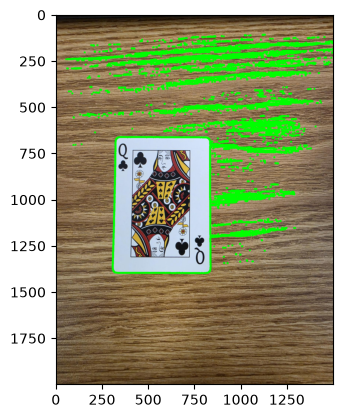

In [93]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps


##Photo Path
path=Path(r"C:\Users\hartmawa\Music\Deep Learning\src\Project\Un_Cropped\Q.jpg")

with Image.open(path) as photo:
    image=np.array(ImageOps.exif_transpose(photo).convert("RGB")) # Convert to numbpy array
    



#Attempt to seperte cards from table, cards should be lighter than table

cutoff=170 #Mess around to find best image cutoff
gray=cv2.cvtColor(image, cv2.COLOR_RGB2GRAY) #Convert to brightness value
gray=cv2.GaussianBlur(gray,(5,5),0)#Smoth out image a bit (Probably will need to mess with this value as we go and see what works better)
_, mask=cv2.threshold(gray,cutoff,255,cv2.THRESH_BINARY) #Create binary cutoff, turn bright pixels white and rest black
contours,_=cv2.findContours(mask,cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE) #Trance outlines and store them as contour so that we can pull them for later


#Now that we have the contours we can plot them over the image to check that they are right

preview=image.copy()#Copy origional image so we can still use it later if we want
cv2.drawContours(preview,contours,-1,(0,255,0),10) # Draw all contours in green

#Plot image with contours
plt.figure()
plt.imshow(preview)


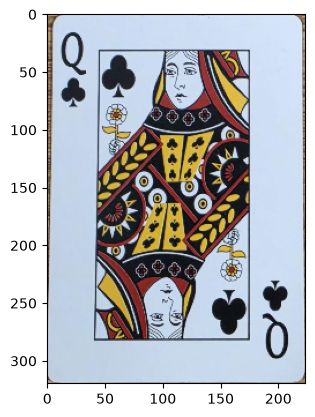

In [94]:
# Actualy crop the card from the image

card_contour=max(contours,key=cv2.contourArea) #Assume that the card is the largest contour in case it finds another one

perimeter = cv2.arcLength(card_contour, True)


#Fit rotated rectangle around the cards
rect = cv2.minAreaRect(card_contour)
points = cv2.boxPoints(rect)
center = points.mean(axis=0)
angles = np.arctan2(points[:, 1] - center[1], points[:, 0] - center[0])
points = points[np.argsort(angles)]

# Start on a short edge so the output card is portrait, not sideways.
side_lengths = np.linalg.norm(points - np.roll(points, -1, axis=0), axis=1)
if side_lengths[0] + side_lengths[2] > side_lengths[1] + side_lengths[3]:
    points = np.roll(points, -1, axis=0)


#Map those corners to an upright rectangle and crop from the color photo.
width, height = 224, 320 #Roughly matches actual card aspect ratio
target = np.float32([[0, 0], [width - 1, 0],[width - 1, height - 1], [0, height - 1]])

matrix = cv2.getPerspectiveTransform(points, target)
crop = cv2.warpPerspective(image, matrix, (width, height))
card_image = Image.fromarray(crop)


#plot card
plt.imshow(card_image)

In [96]:
#Now we can just load in the resnet model and run it!!!
import torch
from torch import nn
from torchvision import models, transforms

model_path = Path.home() / "models" / "resnet18_realcard_combinedface.pth"
values=torch.load(model_path,map_location="cpu",weights_only=True)

#Built the resnest18 with my trained wieghts
ranks = values["ranks"]
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(ranks))
model.load_state_dict(values["model_state_dict"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

#Transfroms to match how we trained
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3), #Make grayscale
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])


(np.float64(-0.5), np.float64(223.5), np.float64(319.5), np.float64(-0.5))

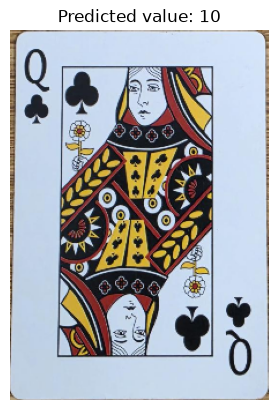

In [97]:
with torch.no_grad():
    inputs = transform(card_image).unsqueeze(0).to(device)
    prediction = model(inputs).argmax(dim=1).item()



plt.figure()
plt.imshow(card_image)
plt.title(f"Predicted value: {ranks[prediction]}")
plt.axis("off")
